In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/mall_loyalty_customers.csv')

In [157]:
df.head()

,customer_id,join_date,gender,age,annual_income_lakh,spending_score,visits_per_month,avg_basket_inr,weekend_share,home_distance_km,app_user,preferred_category,membership_tier
0,CMC00795,2025-04-29,Female,25.0,4.96,58.0,3.7,2426.26,0.353,4.63,No,Food & Beverage,Bronze
1,CMC03329,2024-01-15,Female,25.0,13.09,41.0,1.4,3999.89,0.980,4.83,No,Fashion,Silver
2,CMC03895,2021-02-03,Male,58.0,5.83,60.0,9.4,1282.19,0.357,3.88,No,Fashion,Silver
3,CMC01590,2025-09-12,Male,44.0,11.74,80.0,3.8,3622.47,0.647,7.55,Yes,GROCERY,Silver
4,CMC01083,2025-06-03,Female,41.0,7.82,59.0,6.3,4507.93,0.673,2.04,No,Food & Beverage,Gold


In [158]:
df.shape

(4792, 13)

In [159]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4792 entries, 0 to 4791
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         4792 non-null   object 
 1   join_date           4792 non-null   object 
 2   gender              4757 non-null   object 
 3   age                 4751 non-null   float64
 4   annual_income_lakh  4744 non-null   float64
 5   spending_score      4754 non-null   float64
 6   visits_per_month    4752 non-null   float64
 7   avg_basket_inr      4757 non-null   float64
 8   weekend_share       4761 non-null   float64
 9   home_distance_km    4762 non-null   float64
 10  app_user            4792 non-null   object 
 11  preferred_category  4764 non-null   object 
 12  membership_tier     4767 non-null   object 
dtypes: float64(7), object(6)
memory usage: 486.8+ KB


In [160]:
df.isnull().sum()

,0
customer_id,0
join_date,0
gender,35
age,41
annual_income_lakh,48
spending_score,38
visits_per_month,40
avg_basket_inr,35
weekend_share,31
home_distance_km,30


In [161]:
df.isnull().sum().sum()

np.int64(351)

In [162]:
df.duplicated().sum()

np.int64(70)

In [163]:
df['customer_id'].duplicated().sum()

np.int64(111)

In [164]:
df[df['customer_id'].duplicated(keep=False)].sort_values('customer_id')

,customer_id,join_date,gender,age,annual_income_lakh,spending_score,visits_per_month,avg_basket_inr,weekend_share,home_distance_km,app_user,preferred_category,membership_tier
2686,CMC00022,2025-11-28,Male,57.0,15.83,53.0,3.7,2962.18,0.757,9.61,No,Food & Beverage,Silver
1370,CMC00022,2025-11-28,Male,57.0,15.83,53.0,3.7,2962.18,0.757,9.61,No,Food & Beverage,Silver
1984,CMC00025,2021-05-08,Male,21.0,11.91,66.0,3.6,1925.42,0.652,10.82,Yes,Food & Beverage,Silver
1104,CMC00025,2021-05-08,Male,21.0,11.91,66.0,3.6,1925.42,0.652,10.82,Yes,Food & Beverage,Silver
3314,CMC00061,2024-11-29,Male,28.0,8.27,55.0,5.3,2328.86,0.558,2.31,No,Food & Beverage,Silver
...,...,...,...,...,...,...,...,...,...,...,...,...,...
221,CMC04582,2023-05-06,Female,44.0,9.94,44.0,5.4,4221.35,0.713,7.68,Yes,Fashion,Silver
3723,CMC04603,2022-05-15,Male,36.0,14.53,76.0,7.8,5686.14,0.390,7.37,Yes,Luxury,Platinum
1519,CMC04603,2022-05-15,Male,36.0,14.53,76.0,7.8,5686.14,0.390,7.37,Yes,Luxury,Platinum
1814,CMC04670,2024-12-12,Male,46.0,11.57,65.0,5.1,1683.31,0.730,0.54,Yes,Fashion,Bronze


In [165]:
df[df.duplicated(keep=False)].sort_values('customer_id')

,customer_id,join_date,gender,age,annual_income_lakh,spending_score,visits_per_month,avg_basket_inr,weekend_share,home_distance_km,app_user,preferred_category,membership_tier
2686,CMC00022,2025-11-28,Male,57.0,15.83,53.0,3.7,2962.18,0.757,9.61,No,Food & Beverage,Silver
1370,CMC00022,2025-11-28,Male,57.0,15.83,53.0,3.7,2962.18,0.757,9.61,No,Food & Beverage,Silver
1984,CMC00025,2021-05-08,Male,21.0,11.91,66.0,3.6,1925.42,0.652,10.82,Yes,Food & Beverage,Silver
1104,CMC00025,2021-05-08,Male,21.0,11.91,66.0,3.6,1925.42,0.652,10.82,Yes,Food & Beverage,Silver
1433,CMC00082,2023-06-18,Female,24.0,7.61,69.0,1.4,1668.82,0.428,5.36,Yes,Electronics,Silver
...,...,...,...,...,...,...,...,...,...,...,...,...,...
636,CMC04488,2024-07-06,Female,33.0,6.80,75.0,12.3,2034.01,0.050,6.92,No,Food & Beverage,Bronze
221,CMC04582,2023-05-06,Female,44.0,9.94,44.0,5.4,4221.35,0.713,7.68,Yes,Fashion,Silver
4776,CMC04582,2023-05-06,Female,44.0,9.94,44.0,5.4,4221.35,0.713,7.68,Yes,Fashion,Silver
1519,CMC04603,2022-05-15,Male,36.0,14.53,76.0,7.8,5686.14,0.390,7.37,Yes,Luxury,Platinum


In [166]:
duplicate_ids = df[df['customer_id'].duplicated(keep=False)]

duplicate_ids.groupby('customer_id').size().value_counts()

,count
2,111


In [167]:
duplicate_ids.groupby('customer_id').nunique().max(axis=1).gt(1).sum()

np.int64(33)

In [168]:
conflicting_ids = (
    duplicate_ids.groupby('customer_id')
    .filter(lambda x: x.nunique().max() > 1)
)

conflicting_ids.sort_values('customer_id')

,customer_id,join_date,gender,age,annual_income_lakh,spending_score,visits_per_month,avg_basket_inr,weekend_share,home_distance_km,app_user,preferred_category,membership_tier
3314,CMC00061,2024-11-29,Male,28.0,8.27,55.0,5.3,2328.86,0.558,2.31,No,Food & Beverage,Silver
788,CMC00061,2024-11-29,Male,28.0,8.27,55.0,5.3,2328.86,0.558,2.31,No,F&B,Silver
1992,CMC00355,2025-03-24,Other,NaN,5.03,33.0,2.5,3113.28,0.774,11.76,No,Food & Beverage,Bronze
1502,CMC00355,2025-03-24,Other,18.0,5.03,-5.0,0.8,3235.49,0.774,11.76,No,Food & Beverage,Bronze
4364,CMC00452,2024-08-01,NaN,37.0,7.68,85.0,13.1,1993.41,0.557,3.61,No,Food and Beverage,Silver
...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,CMC04358,2025-11-04,Female,48.0,7.50,61.0,4.6,1830.25,0.584,4.27,Yes,Food & Beverage,Silver
3614,CMC04404,2022-05-20,Male,42.0,6.74,43.0,2.6,2727.64,0.638,15.32,No,Entertainment,Bronze
420,CMC04404,2022-05-20,Male,42.0,6.74,43.0,1.4,2735.12,0.638,15.32,No,Entertainment,Bronze
1814,CMC04670,2024-12-12,Male,46.0,11.57,65.0,5.1,1683.31,0.730,0.54,Yes,Fashion,Bronze


In [169]:
df_original = df.copy()

In [170]:
df = df.drop_duplicates()

In [171]:
df.duplicated().sum()

np.int64(0)

In [172]:
df.shape

(4722, 13)

In [173]:
df['customer_id'].duplicated().sum()

np.int64(41)

In [174]:
df[df['customer_id'].duplicated(keep=False)] \
.groupby('customer_id').size().value_counts()

,count
2,41


In [175]:
df['customer_id'].nunique()

4681

In [176]:
df.shape

(4722, 13)

In [177]:
df.describe()

,age,annual_income_lakh,spending_score,visits_per_month,avg_basket_inr,weekend_share,home_distance_km
count,4681.000000,4.674000e+03,4684.000000,4682.000000,4687.000000,4691.000000,4692.000000
mean,37.018586,4.220893e+03,64.437020,6.307454,3582.637433,1.025198,6.370431
std,18.282911,6.212348e+04,23.090711,3.363760,13988.728439,5.874528,4.516942
min,-2.000000,2.000000e+00,-10.000000,0.000000,250.000000,0.050000,0.300000
25%,27.000000,6.562500e+00,53.000000,3.500000,1637.025000,0.431000,3.030000
50%,37.000000,8.910000e+00,66.000000,6.200000,2373.190000,0.596000,5.310000
75%,45.000000,1.221000e+01,78.000000,8.600000,3621.045000,0.748000,8.590000
max,999.000000,1.374000e+06,999.000000,18.000000,340013.000000,95.000000,35.000000


In [178]:
# Check invalid ages
print("Invalid ages:")
print(df[(df['age'] < 18) | (df['age'] > 100)]['age'].value_counts())

# Check invalid spending scores
print("\nInvalid spending scores:")
print(df[(df['spending_score'] < 1) |
         (df['spending_score'] > 100)]['spending_score'].value_counts())

# Check weekend share entered as percentage
print("\nWeekend share greater than 1:")
print(df[df['weekend_share'] > 1]['weekend_share'].value_counts())

# Check unusually high income
print("\nIncome values greater than 100:")
print(df[df['annual_income_lakh'] > 100]['annual_income_lakh'].sort_values().head(20))

# Check extreme basket values
print("\nBasket values greater than 10000:")
print(df[df['avg_basket_inr'] > 10000]['avg_basket_inr'].sort_values(ascending=False).head(20))

Invalid ages:
age
 999.0    1
 105.0    1
 150.0    1
 12.0     1
 5.0      1
-2.0      1
 9.0      1
Name: count, dtype: int64

Invalid spending scores:
spending_score
 120.0    1
-5.0      1
 999.0    1
 0.0      1
-10.0     1
 105.0    1
 110.0    1
 150.0    1
Name: count, dtype: int64

Weekend share greater than 1:
weekend_share
69.0    3
77.0    2
85.0    2
70.0    2
67.0    2
81.0    2
95.0    2
66.0    1
87.0    1
80.0    1
86.0    1
93.0    1
84.0    1
79.0    1
89.0    1
59.0    1
63.0    1
56.0    1
91.0    1
Name: count, dtype: int64

Income values greater than 100:
1799     437000.0
1850     452000.0
2420     459000.0
3545     463000.0
1849     540000.0
4310     540000.0
2559     573000.0
4475     600000.0
4598     652000.0
2531     673000.0
4205     759000.0
1360     773000.0
3306     815000.0
4372     817000.0
4687     930000.0
804      935000.0
4232     942000.0
2788     962000.0
2591    1039000.0
2000    1190000.0
Name: annual_income_lakh, dtype: float64

Basket values

In [179]:
print("Invalid ages:",
      ((df['age'] < 18) | (df['age'] > 100)).sum())

print("Invalid spending scores:",
      ((df['spending_score'] < 1) |
       (df['spending_score'] > 100)).sum())

print("Weekend share entered as percentage:",
      (df['weekend_share'] > 1).sum())

print("Income values in rupees:",
      (df['annual_income_lakh'] > 100).sum())

print("Extreme basket values:",
      (df['avg_basket_inr'] > 10000).sum())

Invalid ages: 7
Invalid spending scores: 8
Weekend share entered as percentage: 27
Income values in rupees: 24
Extreme basket values: 18


In [180]:
df.loc[df['annual_income_lakh'] > 100,
       'annual_income_lakh'] = (
    df.loc[df['annual_income_lakh'] > 100,
           'annual_income_lakh'] / 100000
)

In [181]:
df['annual_income_lakh'].describe()

,annual_income_lakh
count,4674.000000
mean,9.980573
std,4.915727
min,2.000000
25%,6.550000
50%,8.880000
75%,12.130000
max,35.000000


In [182]:
df.loc[df['weekend_share'] > 1,
       'weekend_share'] /= 100

In [183]:
df['weekend_share'].describe()

,weekend_share
count,4691.000000
mean,0.584119
std,0.207851
min,0.050000
25%,0.431000
50%,0.595000
75%,0.746000
max,0.980000


In [184]:
import numpy as np

df.loc[
    (df['age'] < 18) | (df['age'] > 100),
    'age'
] = np.nan

In [185]:
print("Missing ages:", df['age'].isnull().sum())
print("Minimum age:", df['age'].min())
print("Maximum age:", df['age'].max())

Missing ages: 48
Minimum age: 18.0
Maximum age: 75.0


In [186]:
df.loc[
    (df['spending_score'] < 1) | (df['spending_score'] > 100),
    'spending_score'
] = np.nan

In [187]:
print("Missing spending scores:", df['spending_score'].isnull().sum())
print("Minimum score:", df['spending_score'].min())
print("Maximum score:", df['spending_score'].max())

Missing spending scores: 46
Minimum score: 1.0
Maximum score: 100.0


In [188]:
print("Invalid visits:",
      ((df['visits_per_month'] < 0) |
       (df['visits_per_month'] > 15)).sum())

print("Minimum visits:", df['visits_per_month'].min())
print("Maximum visits:", df['visits_per_month'].max())

Invalid visits: 30
Minimum visits: 0.0
Maximum visits: 18.0


In [189]:
df.loc[
    (df['visits_per_month'] < 0) |
    (df['visits_per_month'] > 15),
    'visits_per_month'
].value_counts().sort_index()

,count
visits_per_month,
15.1,4
15.3,2
15.4,3
15.5,3
15.6,5
15.7,2
16.0,2
16.4,2
16.5,2


In [190]:
df.loc[
    df['visits_per_month'] > 15,
    'visits_per_month'
] = np.nan

In [191]:
print("Missing visits:", df['visits_per_month'].isnull().sum())
print("Minimum visits:", df['visits_per_month'].min())
print("Maximum visits:", df['visits_per_month'].max())

Missing visits: 70
Minimum visits: 0.0
Maximum visits: 14.9


In [192]:
cap_value = df['avg_basket_inr'].quantile(0.995)

print("99.5th percentile:", cap_value)
print("Values above cap:",
      (df['avg_basket_inr'] > cap_value).sum())

99.5th percentile: 7765.383599999966
Values above cap: 24


In [193]:
df['avg_basket_inr'] = df['avg_basket_inr'].clip(upper=cap_value)

In [194]:
print("Maximum basket value:", df['avg_basket_inr'].max())
print("Values above cap:",
      (df['avg_basket_inr'] > cap_value).sum())

Maximum basket value: 7765.383599999966
Values above cap: 0


In [195]:
print("Negative distances:",
      (df['home_distance_km'] < 0).sum())

print("Minimum distance:", df['home_distance_km'].min())
print("Maximum distance:", df['home_distance_km'].max())

Negative distances: 0
Minimum distance: 0.3
Maximum distance: 35.0


In [196]:
categorical_columns = [
    'gender',
    'app_user',
    'preferred_category',
    'membership_tier'
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


gender:
gender
Male      2418
Female    2176
Other       93
NaN         35
Name: count, dtype: int64

app_user:
app_user
Yes    2940
No     1782
Name: count, dtype: int64

preferred_category:
preferred_category
Food & Beverage      1281
Fashion              1175
Entertainment         546
Grocery               461
Electronics           461
Home & Living         421
Luxury                187
NaN                    28
F&B                    23
Apparel                15
FASHON                 15
Food and Beverage      13
ENTERTAINMENT          13
fashion                13
food & beverage        11
GROCERY                 8
grocery                 8
home & living           8
entertainment           7
ELECTRONIC              6
electronics             6
Home and Living         6
LUXURY                  5
Electronic              4
luxury                  1
Name: count, dtype: int64

membership_tier:
membership_tier
Bronze       1883
Silver       1659
Gold          629
Platinum      338
BRONZE

In [197]:
category_mapping = {
    'F&B': 'Food & Beverage',
    'Food and Beverage': 'Food & Beverage',
    'food & beverage': 'Food & Beverage',
    'FASHON': 'Fashion',
    'fashion': 'Fashion',
    'ENTERTAINMENT': 'Entertainment',
    'entertainment': 'Entertainment',
    'GROCERY': 'Grocery',
    'grocery': 'Grocery',
    'home & living': 'Home & Living',
    'Home and Living': 'Home & Living',
    'ELECTRONIC': 'Electronics',
    'Electronic': 'Electronics',
    'electronics': 'Electronics',
    'LUXURY': 'Luxury',
    'luxury': 'Luxury'
}

df['preferred_category'] = (
    df['preferred_category'].replace(category_mapping)
)

In [198]:
tier_mapping = {
    'BRONZE': 'Bronze',
    'bronze': 'Bronze',
    'SILVER': 'Silver',
    'silver': 'Silver',
    'Sliver': 'Silver',
    'GOLD': 'Gold',
    'gold': 'Gold',
    'PLATINUM': 'Platinum',
    'platinum': 'Platinum',
    'Platinium': 'Platinum'
}

df['membership_tier'] = (
    df['membership_tier'].replace(tier_mapping)
)

In [199]:
print(df['preferred_category'].value_counts(dropna=False))

print("\nMembership tiers:")
print(df['membership_tier'].value_counts(dropna=False))

preferred_category
Food & Beverage    1328
Fashion            1203
Entertainment       566
Grocery             477
Electronics         477
Home & Living       435
Luxury              193
NaN                  28
Apparel              15
Name: count, dtype: int64

Membership tiers:
membership_tier
Bronze      1939
Silver      1729
Gold         654
Platinum     352
NaN           25
Basic         23
Name: count, dtype: int64


In [200]:
df['preferred_category'] = df['preferred_category'].replace({
    'Apparel': 'Fashion'
})

In [201]:
duplicate_ids = df[
    df['customer_id'].duplicated(keep=False)
].sort_values('customer_id')

print("Repeated customer IDs:",
      duplicate_ids['customer_id'].nunique())

print("Total rows involved:",
      len(duplicate_ids))

duplicate_ids.head(10)

Repeated customer IDs: 41
Total rows involved: 82


,customer_id,join_date,gender,age,annual_income_lakh,spending_score,visits_per_month,avg_basket_inr,weekend_share,home_distance_km,app_user,preferred_category,membership_tier
3314,CMC00061,2024-11-29,Male,28.0,8.27,55.0,5.3,2328.86,0.558,2.31,No,Food & Beverage,Silver
788,CMC00061,2024-11-29,Male,28.0,8.27,55.0,5.3,2328.86,0.558,2.31,No,Food & Beverage,Silver
4046,CMC00176,2022-04-19,Female,22.0,7.36,80.0,10.1,2291.13,0.651,3.46,Yes,Grocery,Bronze
859,CMC00176,2022-04-19,Female,22.0,7.36,80.0,NaN,2291.13,0.651,3.46,Yes,Grocery,Bronze
4735,CMC00235,2025-08-17,NaN,32.0,6.76,56.0,2.1,3111.80,0.800,7.54,No,Home & Living,Silver
945,CMC00235,2025-08-17,Female,32.0,6.76,56.0,2.1,3111.80,0.800,7.54,No,Home & Living,Silver
1502,CMC00355,2025-03-24,Other,18.0,5.03,NaN,0.8,3235.49,0.774,11.76,No,Food & Beverage,Bronze
1992,CMC00355,2025-03-24,Other,NaN,5.03,33.0,2.5,3113.28,0.774,11.76,No,Food & Beverage,Bronze
3588,CMC00452,2024-08-01,Male,37.0,7.68,85.0,13.1,1993.41,0.557,3.61,No,Food & Beverage,Silver
4364,CMC00452,2024-08-01,NaN,37.0,7.68,85.0,13.1,1993.41,0.557,3.61,No,Food & Beverage,Silver


In [202]:
conflict_counts = (
    duplicate_ids.groupby('customer_id')
    .nunique(dropna=True)
)

conflict_counts[
    (conflict_counts > 1).any(axis=1)
]

,join_date,gender,age,annual_income_lakh,spending_score,visits_per_month,avg_basket_inr,weekend_share,home_distance_km,app_user,preferred_category,membership_tier
customer_id,,,,,,,,,,,,
CMC00355,1,1,1,1,1,2,2,1,1,1,1,1
CMC00535,1,1,1,1,1,2,2,1,1,1,1,1
CMC00950,1,1,1,1,1,2,2,1,1,1,1,1
CMC01021,1,1,1,1,1,2,2,1,1,1,1,1
CMC01171,1,1,1,1,1,2,2,1,1,1,1,1
CMC01205,1,1,1,1,1,2,2,1,1,1,1,1
CMC01362,1,1,1,1,1,2,2,1,1,1,1,1
CMC01372,1,1,1,1,1,2,2,1,1,1,1,1
CMC01498,1,1,1,1,1,2,2,1,1,1,1,1


In [203]:
duplicate_ids.groupby('customer_id')['join_date'].nunique().value_counts()

,count
join_date,
1,41


In [204]:
def get_mode(series):
    modes = series.mode()
    if not modes.empty:
        return modes.iloc[0]
    return np.nan


aggregation_rules = {
    'join_date': 'first',
    'gender': get_mode,
    'age': 'median',
    'annual_income_lakh': 'median',
    'spending_score': 'median',
    'visits_per_month': 'median',
    'avg_basket_inr': 'median',
    'weekend_share': 'median',
    'home_distance_km': 'median',
    'app_user': get_mode,
    'preferred_category': get_mode,
    'membership_tier': get_mode
}

df = df.groupby('customer_id', as_index=False).agg(
    aggregation_rules
)

In [205]:
print("Dataset shape:", df.shape)
print("Unique customers:", df['customer_id'].nunique())
print("Duplicate IDs:", df['customer_id'].duplicated().sum())

Dataset shape: (4681, 13)
Unique customers: 4681
Duplicate IDs: 0


In [206]:
df[df['membership_tier'] == 'Basic'][
    ['customer_id', 'annual_income_lakh',
     'spending_score', 'visits_per_month',
     'avg_basket_inr', 'preferred_category']
]

,customer_id,annual_income_lakh,spending_score,visits_per_month,avg_basket_inr,preferred_category
386,CMC00387,7.98,83.0,11.1,587.55,Food & Beverage
410,CMC00411,5.56,72.0,9.5,1533.47,Entertainment
867,CMC00869,4.43,51.0,7.3,1282.76,Fashion
1185,CMC01189,4.56,86.0,7.6,2000.66,Fashion
1345,CMC01349,5.66,86.0,11.6,2312.98,Entertainment
1418,CMC01423,6.38,56.0,2.4,2494.88,Fashion
1489,CMC01494,3.29,82.0,11.1,2072.62,Grocery
1613,CMC01618,3.01,84.0,7.0,1749.86,Entertainment
1623,CMC01628,7.20,64.0,9.4,1590.59,Food & Beverage
1735,CMC01741,10.18,20.0,3.1,2120.20,Food & Beverage


In [207]:
df['membership_tier'] = df['membership_tier'].replace(
    'Basic', np.nan
)

In [208]:
print(df['membership_tier'].value_counts(dropna=False))

membership_tier
Bronze      1920
Silver      1712
Gold         651
Platinum     350
NaN           48
Name: count, dtype: int64


In [209]:
missing_counts = df.isnull().sum()

print(missing_counts)

customer_id            0
join_date              0
gender                31
age                   45
annual_income_lakh    48
spending_score        43
visits_per_month      66
avg_basket_inr        34
weekend_share         28
home_distance_km      30
app_user               0
preferred_category    28
membership_tier       48
dtype: int64


In [210]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.round(2))

customer_id           0.00
join_date             0.00
gender                0.66
age                   0.96
annual_income_lakh    1.03
spending_score        0.92
visits_per_month      1.41
avg_basket_inr        0.73
weekend_share         0.60
home_distance_km      0.64
app_user              0.00
preferred_category    0.60
membership_tier       1.03
dtype: float64


In [211]:
numerical_columns = [
    'age',
    'annual_income_lakh',
    'spending_score',
    'visits_per_month',
    'avg_basket_inr',
    'weekend_share',
    'home_distance_km'
]

In [212]:
for col in numerical_columns:
    df[col] = df.groupby('membership_tier')[col].transform(
        lambda x: x.fillna(x.median())
    )

In [213]:
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

In [214]:
print(df[numerical_columns].isnull().sum())

age                   0
annual_income_lakh    0
spending_score        0
visits_per_month      0
avg_basket_inr        0
weekend_share         0
home_distance_km      0
dtype: int64


In [215]:
categorical_columns = [
    'gender',
    'preferred_category',
    'membership_tier'
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [216]:
print(df[categorical_columns].isnull().sum())

gender                0
preferred_category    0
membership_tier       0
dtype: int64


In [217]:
print("Dataset shape:", df.shape)

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate customer IDs:")
print(df['customer_id'].duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (4681, 13)

Total missing values:
0

Duplicate rows:
0

Duplicate customer IDs:
0

Data types:
customer_id            object
join_date              object
gender                 object
age                   float64
annual_income_lakh    float64
spending_score        float64
visits_per_month      float64
avg_basket_inr        float64
weekend_share         float64
home_distance_km      float64
app_user               object
preferred_category     object
membership_tier        object
dtype: object


In [218]:
df['join_date'] = pd.to_datetime(df['join_date'])

In [219]:
print(df['join_date'].dtype)
print(df['join_date'].head())

datetime64[ns]
0   2022-05-27
1   2022-02-12
2   2023-02-09
3   2024-02-03
4   2023-07-14
Name: join_date, dtype: datetime64[ns]


In [220]:
df.to_csv('mall_customers_cleaned.csv', index=False)

In [221]:
df.describe()

,join_date,age,annual_income_lakh,spending_score,visits_per_month,avg_basket_inr,weekend_share,home_distance_km
count,4681,4681.000000,4681.000000,4681.000000,4681.000000,4681.000000,4681.000000,4681.000000
mean,2023-06-24 10:50:56.270027776,36.795343,9.989452,64.242470,6.235815,2783.873683,0.585134,6.358762
min,2021-01-01 00:00:00,18.000000,2.000000,1.000000,0.000000,250.000000,0.050000,0.300000
25%,2022-03-31 00:00:00,28.000000,6.610000,53.000000,3.600000,1648.020000,0.436000,3.060000
50%,2023-06-20 00:00:00,37.000000,8.880000,66.000000,6.200000,2377.150000,0.597000,5.340000
75%,2024-09-14 00:00:00,45.000000,12.120000,77.000000,8.400000,3617.460000,0.745000,8.520000
max,2025-12-31 00:00:00,75.000000,35.000000,100.000000,14.900000,7765.383600,0.980000,35.000000
std,NaN,11.400835,4.888748,18.289983,3.243758,1475.905095,0.205951,4.483805


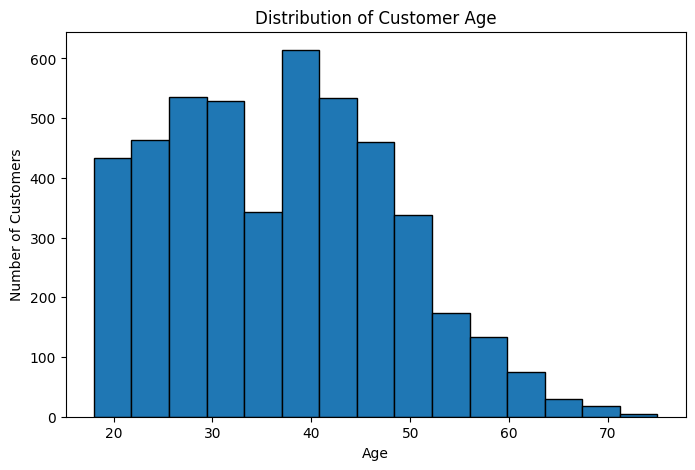

<Figure size 640x480 with 0 Axes>

In [222]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=15, edgecolor='black')

plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()
plt.savefig('outputs/figures/01_age_distribution.png', dpi=300, bbox_inches='tight')

In [223]:
print("Most common age:", df['age'].mode()[0])
print("Minimum age:", df['age'].min())
print("Maximum age:", df['age'].max())

print("\nAge group distribution:")
print(pd.cut(df['age'], bins=[18, 25, 35, 45, 55, 65, 100]).value_counts().sort_index())

Most common age: 18.0
Minimum age: 18.0
Maximum age: 75.0

Age group distribution:
age
(18, 25]      692
(25, 35]     1284
(35, 45]     1377
(45, 55]      864
(55, 65]      224
(65, 100]      36
Name: count, dtype: int64


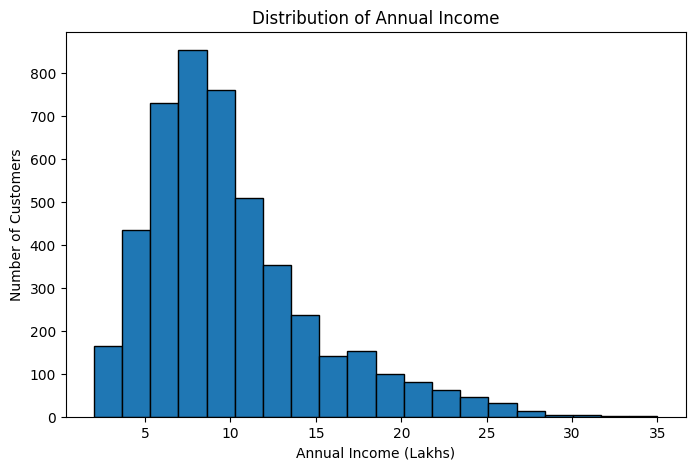

<Figure size 640x480 with 0 Axes>

In [224]:
plt.figure(figsize=(8, 5))

plt.hist(df['annual_income_lakh'], bins=20, edgecolor='black')

plt.title('Distribution of Annual Income')
plt.xlabel('Annual Income (Lakhs)')
plt.ylabel('Number of Customers')

plt.show()
plt.savefig('outputs/figures/02_income_distribution.png', dpi=300, bbox_inches='tight')

In [225]:
print(df['annual_income_lakh'].describe())

count    4681.000000
mean        9.989452
std         4.888748
min         2.000000
25%         6.610000
50%         8.880000
75%        12.120000
max        35.000000
Name: annual_income_lakh, dtype: float64


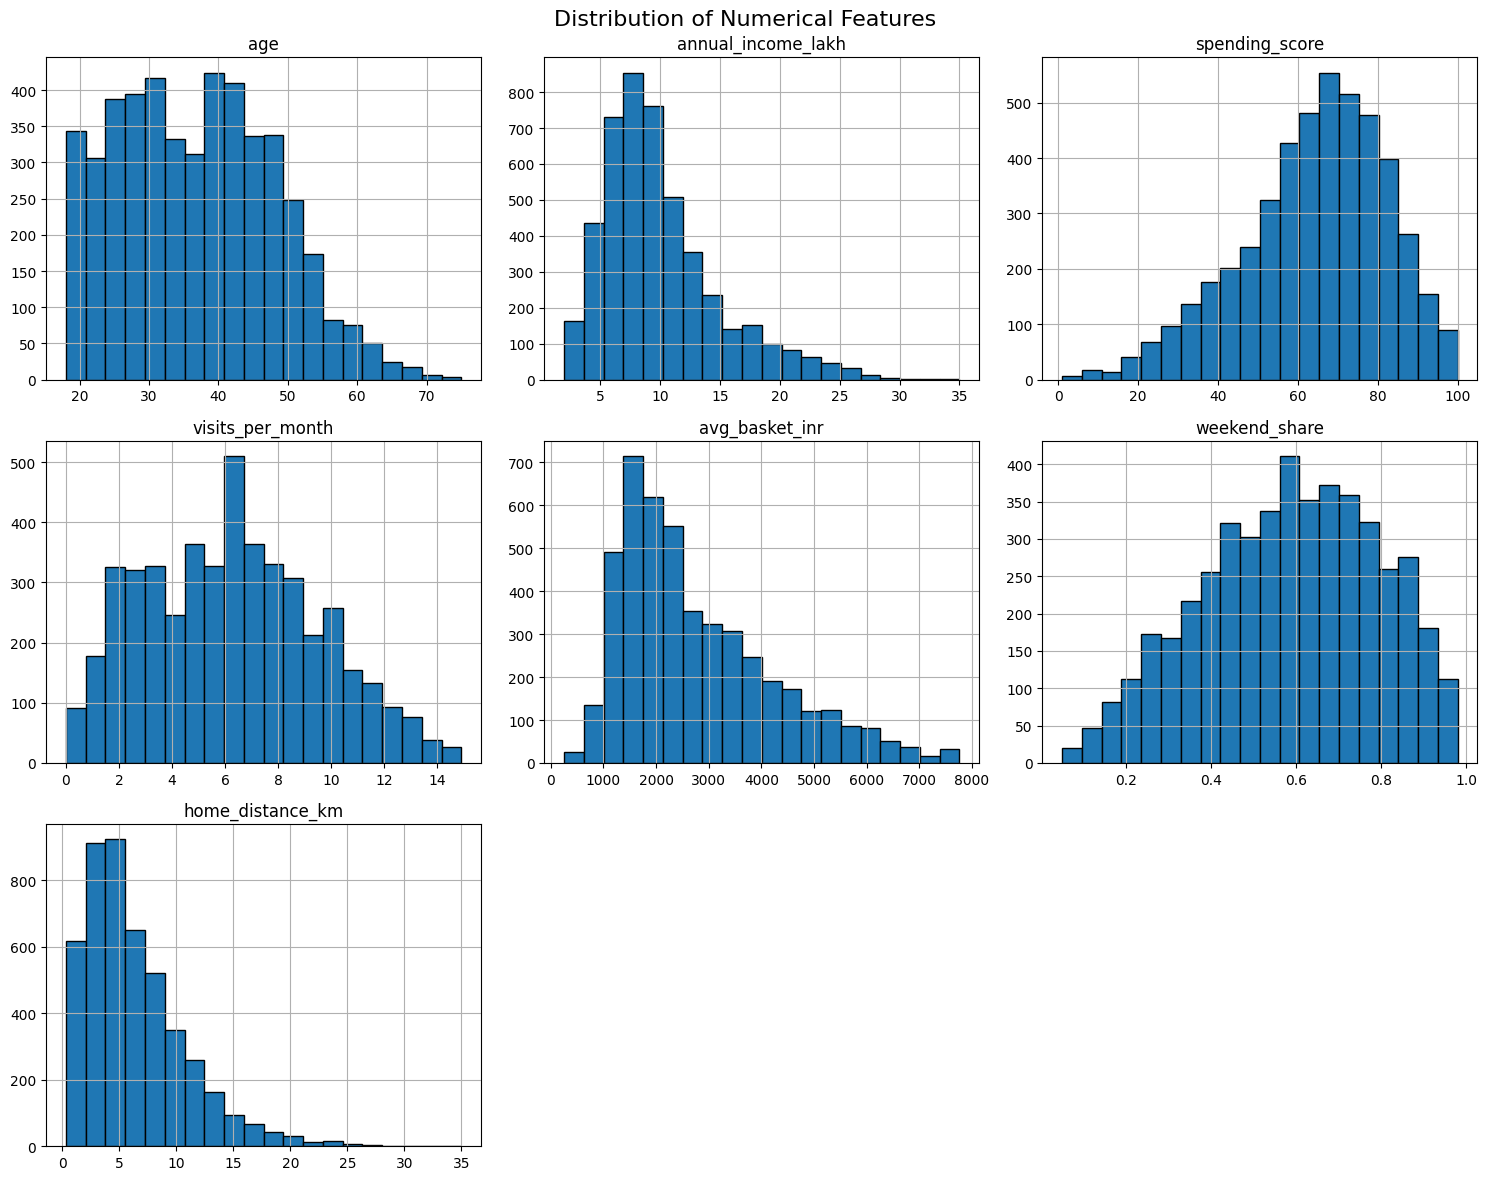

<Figure size 640x480 with 0 Axes>

In [226]:
import matplotlib.pyplot as plt

numerical_columns = [
    'age',
    'annual_income_lakh',
    'spending_score',
    'visits_per_month',
    'avg_basket_inr',
    'weekend_share',
    'home_distance_km'
]

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()
plt.savefig('outputs/figures/03_numerical_features.png', dpi=300, bbox_inches='tight')

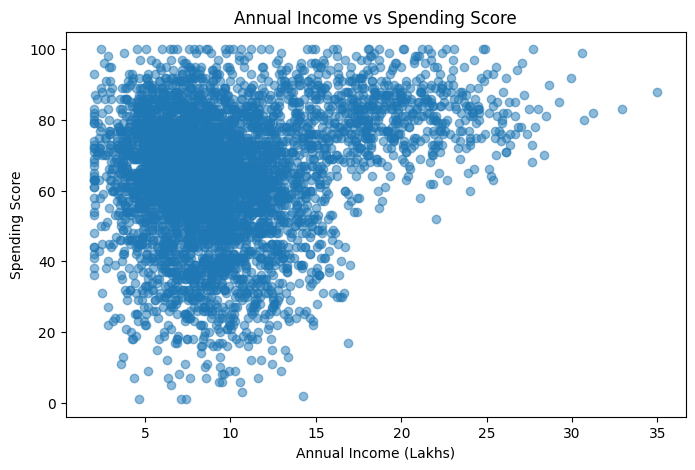

<Figure size 640x480 with 0 Axes>

In [227]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['annual_income_lakh'],
    df['spending_score'],
    alpha=0.5
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (Lakhs)')
plt.ylabel('Spending Score')

plt.show()
plt.savefig('outputs/figures/04_income_vs_spending.png', dpi=300, bbox_inches='tight')

In [228]:
correlation = df['annual_income_lakh'].corr(df['spending_score'])

print("Correlation:", correlation)

Correlation: 0.23445238798180262


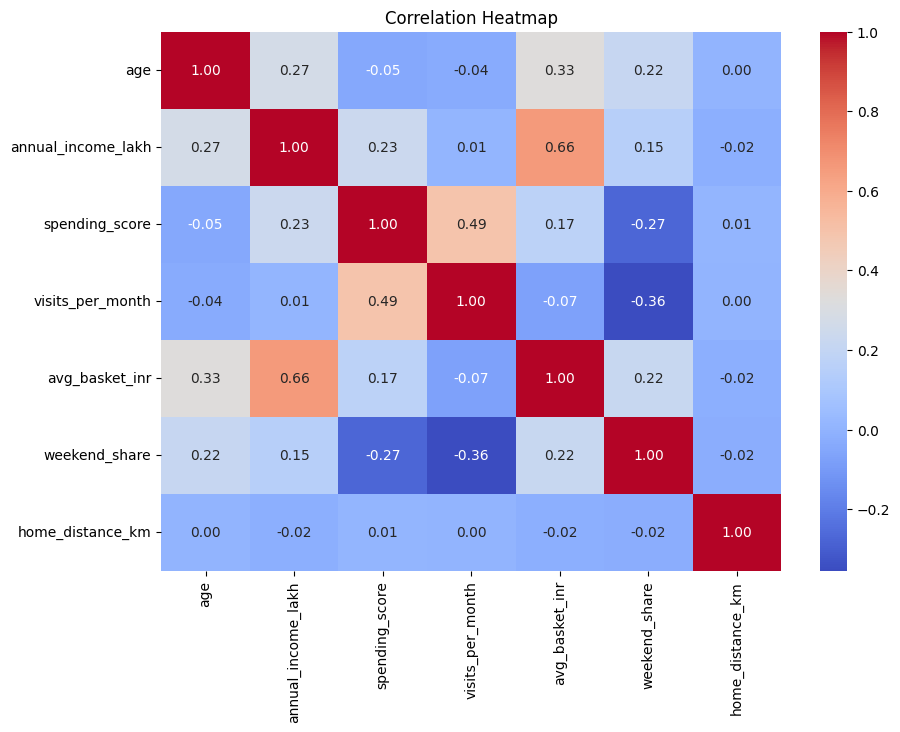

<Figure size 640x480 with 0 Axes>

In [229]:
import seaborn as sns

plt.figure(figsize=(10, 7))

correlation_matrix = df[numerical_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()
plt.savefig('outputs/figures/05_correlation_heatmap.png', dpi=300, bbox_inches='tight')

In [230]:
correlation_matrix = df[numerical_columns].corr()

print(correlation_matrix.round(2))

                     age  annual_income_lakh  spending_score  \
age                 1.00                0.27           -0.05   
annual_income_lakh  0.27                1.00            0.23   
spending_score     -0.05                0.23            1.00   
visits_per_month   -0.04                0.01            0.49   
avg_basket_inr      0.33                0.66            0.17   
weekend_share       0.22                0.15           -0.27   
home_distance_km    0.00               -0.02            0.01   

                    visits_per_month  avg_basket_inr  weekend_share  \
age                            -0.04            0.33           0.22   
annual_income_lakh              0.01            0.66           0.15   
spending_score                  0.49            0.17          -0.27   
visits_per_month                1.00           -0.07          -0.36   
avg_basket_inr                 -0.07            1.00           0.22   
weekend_share                  -0.36            0.22         

In [231]:
print(df['preferred_category'].value_counts())

preferred_category
Food & Beverage    1345
Fashion            1210
Entertainment       561
Electronics         474
Grocery             471
Home & Living       428
Luxury              192
Name: count, dtype: int64


In [232]:
print(df['membership_tier'].value_counts())

membership_tier
Bronze      1968
Silver      1712
Gold         651
Platinum     350
Name: count, dtype: int64


In [233]:
print(df['membership_tier'].value_counts(normalize=True).mul(100).round(2))

membership_tier
Bronze      42.04
Silver      36.57
Gold        13.91
Platinum     7.48
Name: proportion, dtype: float64


In [234]:
print(
    df.groupby('membership_tier')['avg_basket_inr']
      .mean()
      .round(2)
)

membership_tier
Bronze      2074.16
Gold        4524.41
Platinum    5169.05
Silver      2450.24
Name: avg_basket_inr, dtype: float64


In [235]:
df['monthly_spend'] = (
    df['visits_per_month'] * df['avg_basket_inr']
)

In [236]:
print(df[['visits_per_month', 'avg_basket_inr', 'monthly_spend']].head(10))

   visits_per_month  avg_basket_inr  monthly_spend
0               7.2         1514.04      10901.088
1               9.3         4673.88      43467.084
2               0.1         2991.46        299.146
3               8.6         3284.92      28250.312
4               7.9         1256.87       9929.273
5               5.9         4086.88      24112.592
6               9.2         2069.39      19038.388
7               7.5         1337.72      10032.900
8               4.9         1346.10       6595.890
9               6.2         2377.15      14738.330


In [237]:
print(df['monthly_spend'].describe())

count     4681.000000
mean     17010.773962
std      13239.271496
min          0.000000
25%       7819.801000
50%      13510.587000
75%      21782.600000
max      86305.136000
Name: monthly_spend, dtype: float64


In [238]:
reference_date = pd.Timestamp('2026-11-04')

df['tenure_years'] = (
    (reference_date - df['join_date']).dt.days / 365.25
)

In [239]:
print(df[['join_date', 'tenure_years']].head(10))

   join_date  tenure_years
0 2022-05-27      4.440794
1 2022-02-12      4.725530
2 2023-02-09      3.734428
3 2024-02-03      2.751540
4 2023-07-14      3.310062
5 2021-01-08      5.820671
6 2022-04-06      4.580424
7 2025-11-03      1.002053
8 2021-01-03      5.834360
9 2022-01-27      4.769336


In [240]:
print(df['tenure_years'].describe())

count    4681.000000
mean        3.363581
std         1.437851
min         0.843258
25%         2.138261
50%         3.375770
75%         4.596851
max         5.839836
Name: tenure_years, dtype: float64


In [241]:
import numpy as np

df['log_avg_basket'] = np.log1p(df['avg_basket_inr'])

In [242]:
print(df[['avg_basket_inr', 'log_avg_basket']].head(10))

   avg_basket_inr  log_avg_basket
0         1514.04        7.323197
1         4673.88        8.449959
2         2991.46        8.003851
3         3284.92        8.097402
4         1256.87        7.137175
5         4086.88        8.315782
6         2069.39        7.635492
7         1337.72        7.199469
8         1346.10        7.205709
9         2377.15        7.774078


In [243]:
print(df['log_avg_basket'].describe())

count    4681.000000
mean        7.796911
std         0.525108
min         5.525453
25%         7.407936
50%         7.774078
75%         8.193804
max         8.957560
Name: log_avg_basket, dtype: float64


In [244]:
features = [
    'age',
    'annual_income_lakh',
    'spending_score',
    'visits_per_month',
    'monthly_spend',
    'tenure_years'
]

X = df[features].copy()

print(X.head())
print("\nShape:", X.shape)

    age  annual_income_lakh  spending_score  visits_per_month  monthly_spend  \
0  21.0                4.94            60.0               7.2      10901.088   
1  60.0                4.84            47.0               9.3      43467.084   
2  18.0                9.76            50.0               0.1        299.146   
3  29.0               15.89            48.0               8.6      28250.312   
4  28.0                9.66            50.0               7.9       9929.273   

   tenure_years  
0      4.440794  
1      4.725530  
2      3.734428  
3      2.751540  
4      3.310062  

Shape: (4681, 6)


In [245]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data:\n")
print(X_scaled[:5])

Scaled data:

[[-1.38560288 -1.03298249 -0.23198069  0.29727499 -0.46153134  0.7492627 ]
 [ 2.03556454 -1.0534398  -0.94282822  0.94474148  1.99853417  0.94731307]
 [-1.64876961 -0.04693973 -0.77878648 -1.89177839 -1.26241186  0.25794544]
 [-0.68382495  1.20709389 -0.88814764  0.72891932  0.84904511 -0.42570919]
 [-0.77154719 -0.06739705 -0.77878648  0.51309716 -0.53494314 -0.03722578]]


In [246]:
print("Mean of scaled features:")
print(X_scaled.mean(axis=0).round(2))

print("\nStandard deviation of scaled features:")
print(X_scaled.std(axis=0).round(2))

Mean of scaled features:
[ 0. -0.  0.  0. -0.  0.]

Standard deviation of scaled features:
[1. 1. 1. 1. 1. 1.]


In [247]:

from sklearn.cluster import KMeans

inertia = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

print(inertia)


[21318.789409020417, 16788.18951686561, 14874.843741814166, 13501.073382091308, 12408.394755900816, 11687.864283437359, 11044.806380717646, 10517.795115818502, 10008.893079460495]


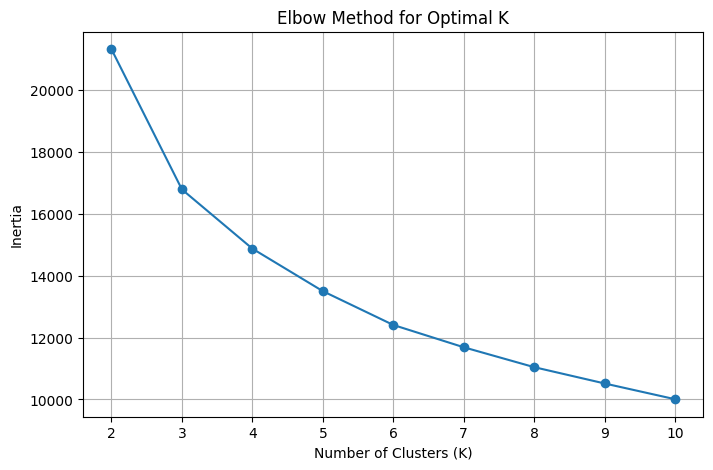

<Figure size 640x480 with 0 Axes>

In [248]:
import matplotlib.pyplot as plt

k_values = range(2, 11)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker='o',
    linestyle='-'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(k_values)
plt.grid(True)

plt.show()
plt.savefig('outputs/figures/06_elbow_plot.png', dpi=300, bbox_inches='tight')

In [249]:
from sklearn.metrics import silhouette_score

In [250]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

print(silhouette_scores)

[np.float64(0.2783704812452919), np.float64(0.2351789701934406), np.float64(0.2074983763098844), np.float64(0.20093279286842716), np.float64(0.19354728859245388), np.float64(0.18646951749885088), np.float64(0.18266882863205222), np.float64(0.17968022902905342), np.float64(0.17777990298633972)]


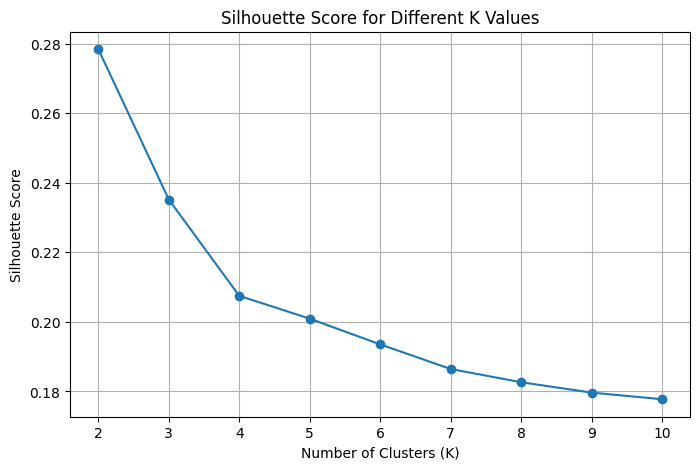

<Figure size 640x480 with 0 Axes>

In [251]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o',
    linestyle='-'
)

plt.title('Silhouette Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()
plt.savefig('outputs/figures/07_silhouette_score.png', dpi=300, bbox_inches='tight')

In [252]:
from sklearn.metrics import davies_bouldin_score

In [253]:
db_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = davies_bouldin_score(X_scaled, labels)

    db_scores.append(score)

print(db_scores)

[np.float64(1.405559540472852), np.float64(1.490047663386277), np.float64(1.5036693022405703), np.float64(1.4963453243211624), np.float64(1.3824708167645108), np.float64(1.4566485466292687), np.float64(1.4692944347115202), np.float64(1.4718830437257227), np.float64(1.5112817058906196)]


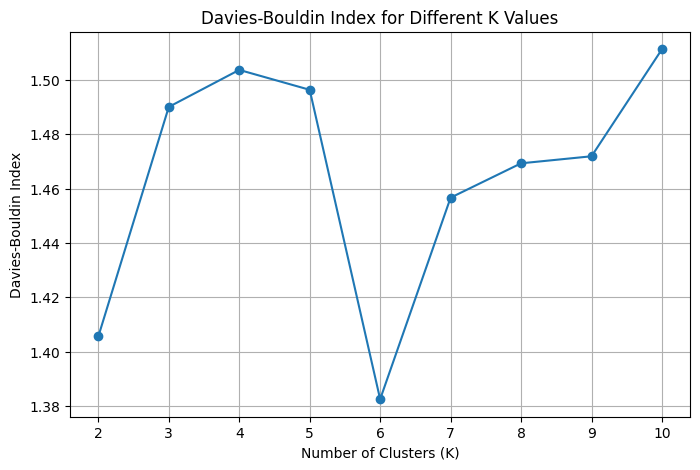

<Figure size 640x480 with 0 Axes>

In [254]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    db_scores,
    marker='o',
    linestyle='-'
)

plt.title('Davies-Bouldin Index for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Davies-Bouldin Index')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()
plt.savefig('outputs/figures/08_davies_bouldin.png', dpi=300, bbox_inches='tight')

In [255]:
from sklearn.metrics import calinski_harabasz_score

In [256]:
ch_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = calinski_harabasz_score(X_scaled, labels)

    ch_scores.append(score)

print(ch_scores)

[np.float64(1485.2621987790221), np.float64(1574.0594149556212), np.float64(1384.6325355751055), np.float64(1262.853185101305), np.float64(1181.3549965597588), np.float64(1092.946569824039), np.float64(1030.0057399691088), np.float64(975.4758539801312), np.float64(937.3769281126697)]


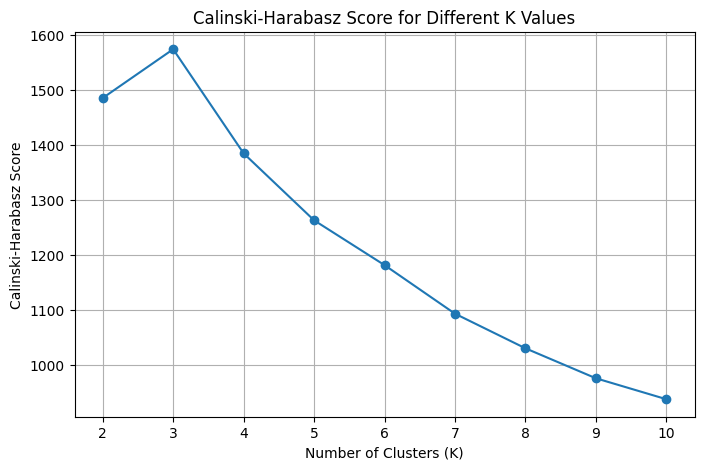

<Figure size 640x480 with 0 Axes>

In [257]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    ch_scores,
    marker='o',
    linestyle='-'
)

plt.title('Calinski-Harabasz Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Calinski-Harabasz Score')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()
plt.savefig('outputs/figures/09_calinski_harabasz.png', dpi=300, bbox_inches='tight')

In [258]:
from sklearn.metrics import adjusted_rand_score

In [259]:
ari_scores = []

for k in range(2, 11):

    model1 = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model2 = KMeans(
        n_clusters=k,
        random_state=100,
        n_init=10
    )

    labels1 = model1.fit_predict(X_scaled)
    labels2 = model2.fit_predict(X_scaled)

    ari = adjusted_rand_score(labels1, labels2)

    ari_scores.append(ari)

print(ari_scores)

[0.9990487448966682, 0.9985468215975263, 0.99939385093993, 0.9949540043770139, 0.9669786081266554, 0.8507120296072626, 0.9129840421034348, 0.6359865766819724, 0.7945974341503441]


In [260]:
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = final_kmeans.fit_predict(X_scaled)

print(df['Cluster'].value_counts().sort_index())

Cluster
0    1010
1    2100
2    1571
Name: count, dtype: int64


In [261]:
from sklearn.decomposition import PCA

In [262]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Original shape: (4681, 6)
PCA shape: (4681, 2)
Explained variance ratio: [0.37066373 0.21599617]
Total explained variance: 0.5866599012453312


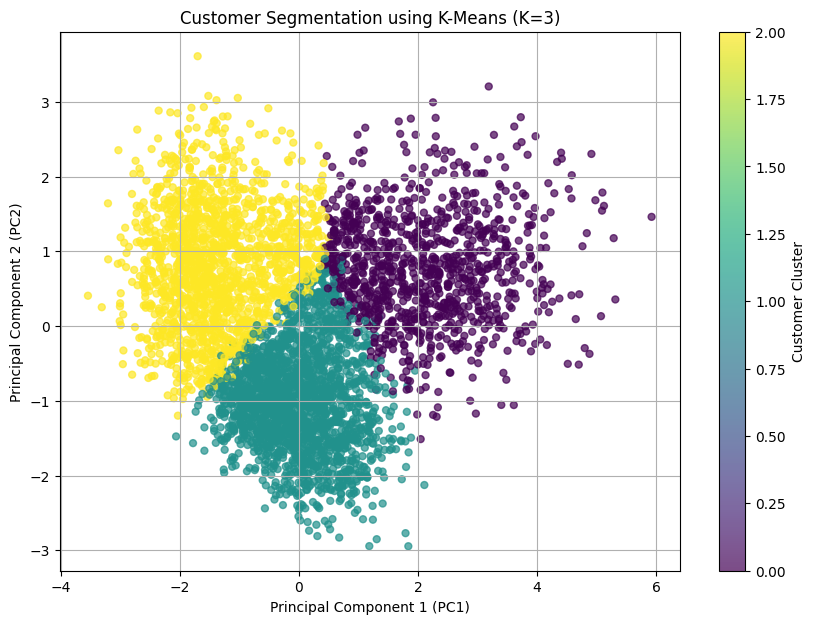

<Figure size 640x480 with 0 Axes>

In [263]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    s=25,
    alpha=0.7
)

plt.title('Customer Segmentation using K-Means (K=3)')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.colorbar(label='Customer Cluster')
plt.grid(True)

plt.show()
plt.savefig('outputs/figures/10_pca_clusters.png', dpi=300, bbox_inches='tight')

In [264]:
cluster_profile = df.groupby('Cluster')[features].mean().round(2)

print(cluster_profile)

           age  annual_income_lakh  spending_score  visits_per_month  \
Cluster                                                                
0        43.82               16.78           77.82              7.56   
1        31.76                7.25           70.92              8.08   
2        39.01                9.28           46.59              2.92   

         monthly_spend  tenure_years  
Cluster                               
0             36554.27          3.36  
1             14371.77          3.33  
2              7973.84          3.42  


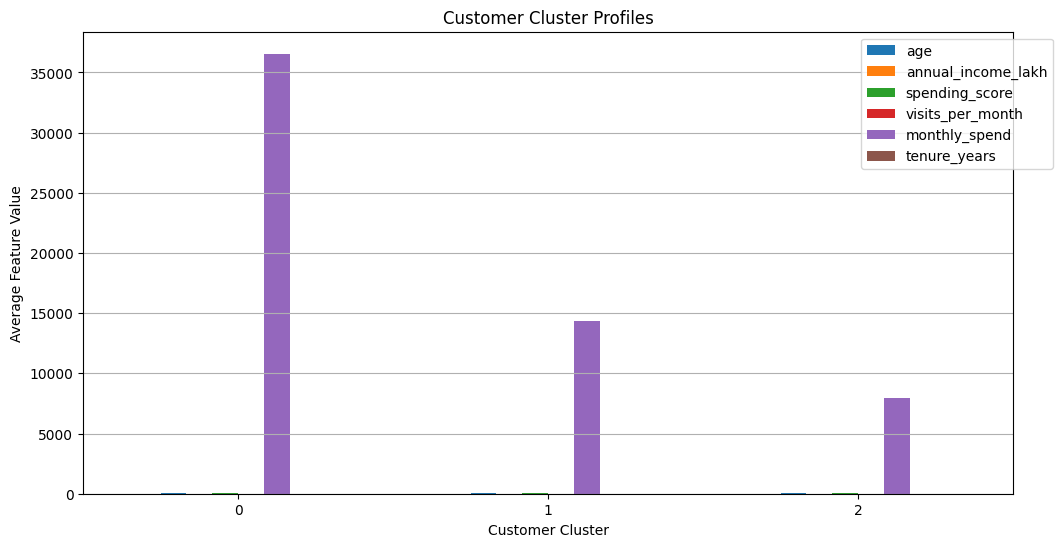

<Figure size 640x480 with 0 Axes>

In [265]:
cluster_profile.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Customer Cluster Profiles')
plt.xlabel('Customer Cluster')
plt.ylabel('Average Feature Value')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1))
plt.grid(axis='y')

plt.show()
plt.savefig('outputs/figures/11_cluster_profiles.png', dpi=300, bbox_inches='tight')

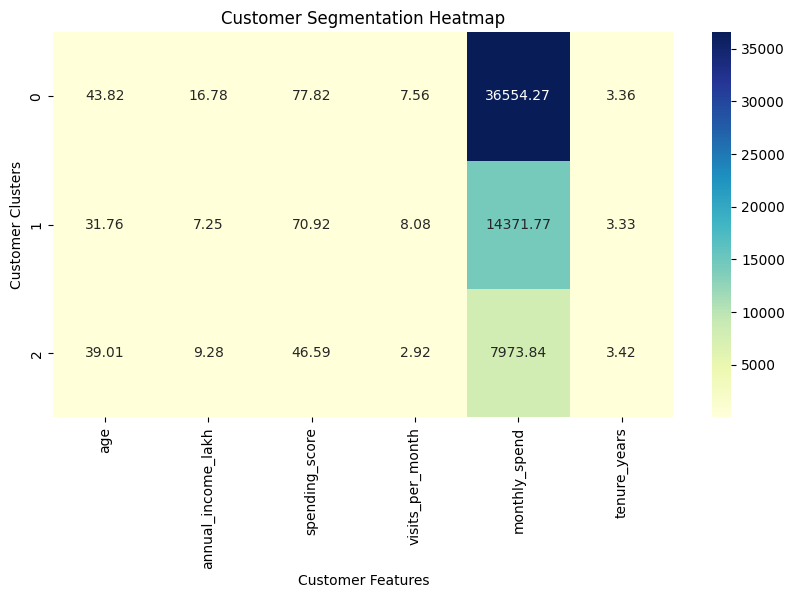

<Figure size 640x480 with 0 Axes>

In [266]:
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.heatmap(
    cluster_profile,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f'
)

plt.title('Customer Segmentation Heatmap')
plt.xlabel('Customer Features')
plt.ylabel('Customer Clusters')

plt.show()
plt.savefig('outputs/figures/12_cluster_heatmap.png', dpi=300, bbox_inches='tight')

In [267]:
from sklearn.preprocessing import StandardScaler

scaler_heatmap = StandardScaler()

cluster_profile_scaled = pd.DataFrame(
    scaler_heatmap.fit_transform(cluster_profile),
    columns=cluster_profile.columns,
    index=cluster_profile.index
)

print(cluster_profile_scaled.round(2))

          age  annual_income_lakh  spending_score  visits_per_month  \
Cluster                                                               
0        1.13                1.39            0.95              0.59   
1       -1.30               -0.94            0.43              0.82   
2        0.16               -0.44           -1.38             -1.41   

         monthly_spend  tenure_years  
Cluster                               
0                 1.38         -0.27  
1                -0.43         -1.07  
2                -0.95          1.34  


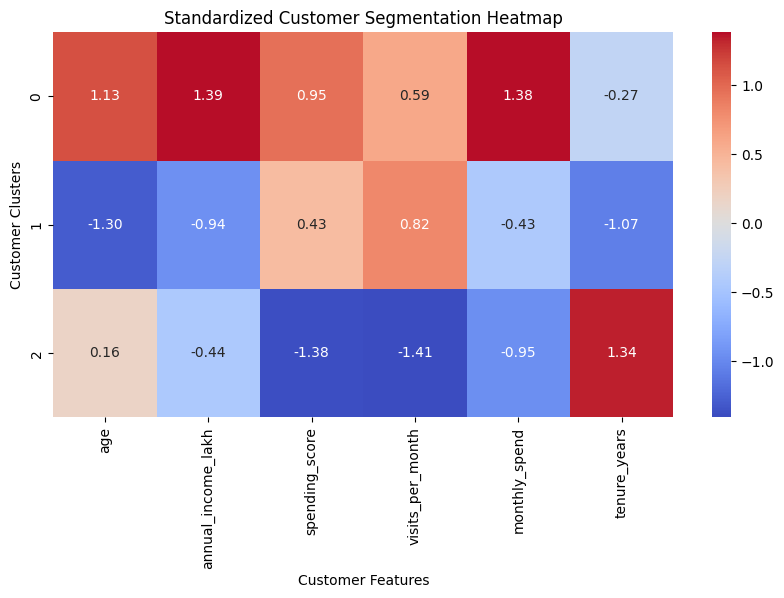

<Figure size 640x480 with 0 Axes>

In [268]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    cluster_profile_scaled,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title('Standardized Customer Segmentation Heatmap')
plt.xlabel('Customer Features')
plt.ylabel('Customer Clusters')

plt.show()
plt.savefig('outputs/figures/13_standardized_heatmap.png', dpi=300, bbox_inches='tight')

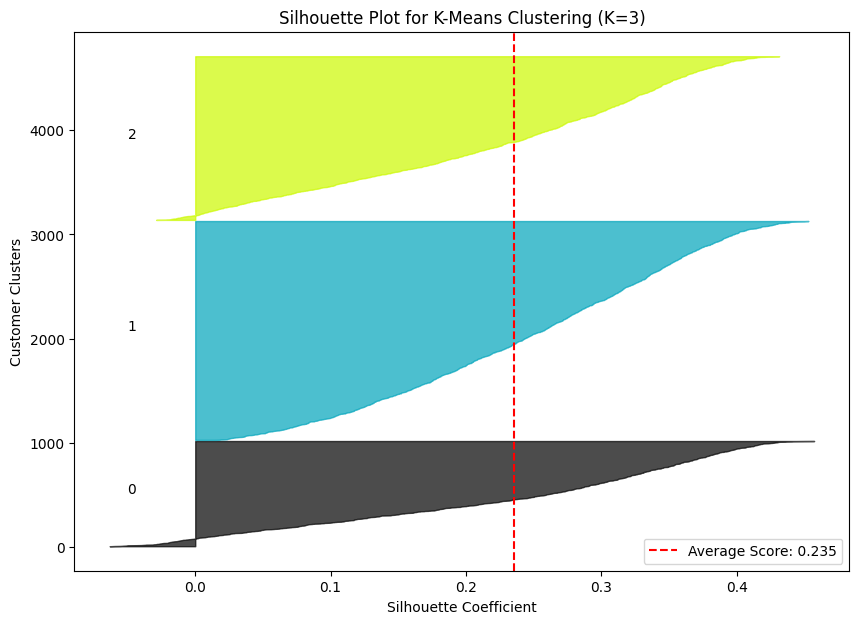

<Figure size 640x480 with 0 Axes>

In [269]:
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import numpy as np

# Calculate individual silhouette values
sample_silhouette_values = silhouette_samples(
    X_scaled, df['Cluster']
)

# Calculate average silhouette score
average_silhouette_score = silhouette_score(
    X_scaled, df['Cluster']
)

# Create the plot
plt.figure(figsize=(10, 7))

y_lower = 10

for i in range(3):

    # Get silhouette values for each cluster
    cluster_values = sample_silhouette_values[
        df['Cluster'].to_numpy() == i
    ]

    cluster_values.sort()

    size_cluster_i = cluster_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = plt.cm.nipy_spectral(float(i) / 3)

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_values,
        facecolor=color,
        edgecolor=color,
        alpha=0.7
    )

    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

    y_lower = y_upper + 10

# Show average silhouette score
plt.axvline(
    x=average_silhouette_score,
    color="red",
    linestyle="--",
    label=f"Average Score: {average_silhouette_score:.3f}"
)

plt.title("Silhouette Plot for K-Means Clustering (K=3)")
plt.xlabel("Silhouette Coefficient")
plt.ylabel("Customer Clusters")
plt.legend()
plt.show()
plt.savefig('outputs/figures/14_silhouette_plot.png', dpi=300, bbox_inches='tight')

In [270]:
import os

os.makedirs('outputs/figures', exist_ok=True)

print("Folders created successfully!")


Folders created successfully!


In [271]:
plt.savefig('outputs/figures/elbow_plot.png',
            dpi=300, bbox_inches='tight')

plt.show()

<Figure size 640x480 with 0 Axes>

In [272]:
import os

print(os.listdir('outputs/figures'))

['05_correlation_heatmap.png', '03_numerical_features.png', '07_silhouette_score.png', '01_age_distribution.png', '12_cluster_heatmap.png', '04_income_vs_spending.png', '13_standardized_heatmap.png', '08_davies_bouldin.png', '10_pca_clusters.png', '06_elbow_plot.png', '09_calinski_harabasz.png', 'elbow_plot.png', '14_silhouette_plot.png', '11_cluster_profiles.png', '02_income_distribution.png']


In [273]:
!zip -r figures.zip outputs/figures

  adding: outputs/figures/ (stored 0%)
  adding: outputs/figures/05_correlation_heatmap.png (deflated 98%)
  adding: outputs/figures/03_numerical_features.png (deflated 98%)
  adding: outputs/figures/07_silhouette_score.png (deflated 98%)
  adding: outputs/figures/01_age_distribution.png (deflated 98%)
  adding: outputs/figures/12_cluster_heatmap.png (deflated 98%)
  adding: outputs/figures/04_income_vs_spending.png (deflated 98%)
  adding: outputs/figures/13_standardized_heatmap.png (deflated 98%)
  adding: outputs/figures/08_davies_bouldin.png (deflated 98%)
  adding: outputs/figures/10_pca_clusters.png (deflated 98%)
  adding: outputs/figures/06_elbow_plot.png (deflated 98%)
  adding: outputs/figures/09_calinski_harabasz.png (deflated 98%)
  adding: outputs/figures/elbow_plot.png (deflated 98%)
  adding: outputs/figures/14_silhouette_plot.png (deflated 98%)
  adding: outputs/figures/11_cluster_profiles.png (deflated 98%)
  adding: outputs/figures/02_income_distribution.png (deflated

In [274]:
from google.colab import files
files.download('figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [275]:
import pandas as pd

metrics_df = pd.DataFrame({
    'K': range(2, 11),
    'Inertia': inertia,
    'Silhouette': silhouette_scores,
    'Davies_Bouldin': db_scores,
    'Calinski_Harabasz': ch_scores,
    'ARI_Stability': ari_scores
})

os.makedirs('outputs/reports', exist_ok=True)

metrics_df.to_csv(
    'outputs/reports/metrics.csv',
    index=False
)

print(metrics_df)
print("metrics.csv saved successfully!")

    K       Inertia  Silhouette  Davies_Bouldin  Calinski_Harabasz  \
0   2  21318.789409    0.278370        1.405560        1485.262199   
1   3  16788.189517    0.235179        1.490048        1574.059415   
2   4  14874.843742    0.207498        1.503669        1384.632536   
3   5  13501.073382    0.200933        1.496345        1262.853185   
4   6  12408.394756    0.193547        1.382471        1181.354997   
5   7  11687.864283    0.186470        1.456649        1092.946570   
6   8  11044.806381    0.182669        1.469294        1030.005740   
7   9  10517.795116    0.179680        1.471883         975.475854   
8  10  10008.893079    0.177780        1.511282         937.376928   

   ARI_Stability  
0       0.999049  
1       0.998547  
2       0.999394  
3       0.994954  
4       0.966979  
5       0.850712  
6       0.912984  
7       0.635987  
8       0.794597  
metrics.csv saved successfully!


In [276]:
import json
import os

summary = {
    "project": "Shopping Mall Customer Segmentation",
    "algorithm": "K-Means Clustering",
    "optimal_k": 3,
    "total_customers": 4681,
    "cluster_sizes": {
        "Cluster 0": 1010,
        "Cluster 1": 2100,
        "Cluster 2": 1571
    },
    "silhouette_score": 0.2075,
    "pca_variance_explained": 0.58666,
    "personas": {
        "Cluster 0": "Premium High-Spending Customers",
        "Cluster 1": "Young Frequent Shoppers",
        "Cluster 2": "Budget-Conscious Occasional Shoppers"
    }
}

os.makedirs('outputs/reports', exist_ok=True)

with open('outputs/reports/summary.json', 'w') as f:
    json.dump(summary, f, indent=4)

print("summary.json saved successfully!")

summary.json saved successfully!


In [277]:
import os
import joblib

os.makedirs('models', exist_ok=True)

# Save the trained K-Means model
joblib.dump(final_kmeans, 'models/kmeans_model.pkl')

# Save the scaler used during training
joblib.dump(scaler, 'models/scaler.pkl')

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [278]:
readme = """
# Shopping Mall Customer Segmentation

## 1. Project Overview
This project uses K-Means Clustering to divide shopping mall
customers into groups based on their age, income, spending
score, shopping visits, monthly spending, and membership tenure.

## 2. Dataset
- Original customers: 4,792
- Customers used after cleaning: 4,681
- Features used: 6

## 3. Methodology
1. Data cleaning
2. Exploratory Data Analysis (EDA)
3. Feature engineering
4. Feature scaling
5. K-Means clustering
6. Model evaluation
7. PCA visualization
8. Customer profiling

## 4. Model Results
- Algorithm: K-Means
- Selected clusters: 3
- Silhouette Score: 0.2075
- PCA variance explained: 58.67%

## 5. Customer Segments

| Cluster | Customers | Customer Type |
|---|---:|---|
| 0 | 1,010 | Premium High-Spending Customers |
| 1 | 2,100 | Young Frequent Shoppers |
| 2 | 1,571 | Budget-Conscious Occasional Shoppers |

## 6. Five Key Insights

1. Cluster 0 has the highest average monthly spending
   at approximately Rs. 36,554.

2. Cluster 1 is the largest customer group, with
   2,100 customers.

3. Cluster 1 visits the mall most frequently,
   averaging 8.08 visits per month.

4. Cluster 2 has the lowest average monthly spending,
   approximately Rs. 7,974.

5. Cluster 0 has the highest average annual income,
   approximately Rs. 16.78 lakh.

## 7. Three Business Recommendations

1. Offer VIP rewards and premium services to Cluster 0.

2. Provide loyalty points, seasonal offers, and
   shopping rewards to Cluster 1.

3. Offer discounts, combo deals, and value packages
   to Cluster 2.

## 8. Project Limitations
The Silhouette Score is approximately 0.2075,
indicating that some customer groups overlap.
The clustering results should be interpreted with care.

## 9. Project Deliverables
- Executed Jupyter/Colab notebook
- Charts in outputs/figures/
- metrics.csv and summary.json in outputs/reports/
- Trained model and scaler in models/
- README.md
"""

with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [279]:
import os

for folder in ['outputs/figures', 'outputs/reports', 'models']:
    print(f"\n📁 {folder}")
    for file in sorted(os.listdir(folder)):
        print("  ✅", file)

print("\n📄 README.md:", os.path.exists('README.md'))
print("📓 Notebook is your current Colab file.")


📁 outputs/figures
  ✅ 01_age_distribution.png
  ✅ 02_income_distribution.png
  ✅ 03_numerical_features.png
  ✅ 04_income_vs_spending.png
  ✅ 05_correlation_heatmap.png
  ✅ 06_elbow_plot.png
  ✅ 07_silhouette_score.png
  ✅ 08_davies_bouldin.png
  ✅ 09_calinski_harabasz.png
  ✅ 10_pca_clusters.png
  ✅ 11_cluster_profiles.png
  ✅ 12_cluster_heatmap.png
  ✅ 13_standardized_heatmap.png
  ✅ 14_silhouette_plot.png
  ✅ elbow_plot.png

📁 outputs/reports
  ✅ metrics.csv
  ✅ summary.json

📁 models
  ✅ kmeans_model.pkl
  ✅ scaler.pkl

📄 README.md: True
📓 Notebook is your current Colab file.


In [280]:
!zip -r Shopping_Mall_Customer_Segmentation.zip \
    outputs models README.md

  adding: outputs/ (stored 0%)
  adding: outputs/reports/ (stored 0%)
  adding: outputs/reports/metrics.csv (deflated 43%)
  adding: outputs/reports/summary.json (deflated 47%)
  adding: outputs/figures/ (stored 0%)
  adding: outputs/figures/05_correlation_heatmap.png (deflated 98%)
  adding: outputs/figures/03_numerical_features.png (deflated 98%)
  adding: outputs/figures/07_silhouette_score.png (deflated 98%)
  adding: outputs/figures/01_age_distribution.png (deflated 98%)
  adding: outputs/figures/12_cluster_heatmap.png (deflated 98%)
  adding: outputs/figures/04_income_vs_spending.png (deflated 98%)
  adding: outputs/figures/13_standardized_heatmap.png (deflated 98%)
  adding: outputs/figures/08_davies_bouldin.png (deflated 98%)
  adding: outputs/figures/10_pca_clusters.png (deflated 98%)
  adding: outputs/figures/06_elbow_plot.png (deflated 98%)
  adding: outputs/figures/09_calinski_harabasz.png (deflated 98%)
  adding: outputs/figures/elbow_plot.png (deflated 98%)
  adding: outp

In [281]:
from google.colab import files

files.download('Shopping_Mall_Customer_Segmentation.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>